# Naver Place — Data Stages / 데이터 단계

Every stage the Naver data passes through, from the raw scrape to the tables in the proposal.

**Scope: Naver Place only.** The cross-cultural branch (Google Maps, foreign tourists, H1–H5)
is paused; see `notebooks/data_overview.ipynb` for that one.

```
02_scrape_naver.py      ──►  data/naver_reviews_raw.json      23 places, raw review objects
09_build_naver_dataset  ──►  data/analysis/naver/naver_dataset.csv    the modelling dataframe
09_02_naver_models.py   ──►  data/analysis/naver/model*.csv           M1–M4 coefficients
09_03_rating_checks.py  ──►  data/analysis/rating_checks.csv          sentiment vs stars
10_descriptive_tables   ──►  data/analysis/naver/table{1,2,3}_*.csv   표 1–3 + proposal/tables_naver.tex
```

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 60)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA, NAVER = ROOT / "data", ROOT / "data" / "analysis" / "naver"

def read(path, **kw):
    p = Path(path)
    if not p.is_absolute():
        p = NAVER / p
    return pd.read_csv(p, encoding="utf-8-sig", **kw) if p.exists() else None

print("project root:", ROOT)

project root: C:\Users\crono\Documents\Python\personal_projects\Projects\topSongsProject\ReviewsProject


## 1. Raw scrape / 원자료

`02_scrape_naver.py` writes one object per attraction, each holding its review list.
Nothing is cleaned at this point — this is what Naver's DOM gave us.

In [2]:
raw_path = DATA / "naver_reviews_raw.json"
raw = json.loads(raw_path.read_text(encoding="utf-8"))

print(f"{raw_path.name}:  {raw_path.stat().st_size/1e6:.1f} MB,  {len(raw)} places")
print("place keys :", sorted(raw[0].keys()))
print("review keys:", sorted(raw[0]["reviews"][0].keys()))

per_place = (pd.DataFrame([{"place": p["name"],
                            "reviews": len(p.get("reviews") or []),
                            "scraped_at": p.get("scraped_at"),
                            "sort": p.get("sort")} for p in raw])
             .sort_values("reviews", ascending=False).reset_index(drop=True))
print(f"\ntotal raw reviews: {per_place['reviews'].sum():,}")
per_place

naver_reviews_raw.json:  14.9 MB,  30 places
place keys : ['name', 'naver_id', 'reviews', 'scraped_at', 'sort', 'url']
review keys: ['language', 'n_photos', 'nickname', 'profile_url', 'rating', 'reaction_types', 'reactions', 'tags', 'text', 'user_followers', 'user_photos', 'user_reviews', 'verification', 'visit_count', 'visit_date', 'visit_date_full', 'visit_keywords']

total raw reviews: 14,470


,place,reviews,scraped_at,sort
0,서울스카이,1103,2026-10-07T10:37:59.884742,default
1,남산골한옥마을,1077,2026-10-07T09:44:53.877237,default
2,에버랜드,1019,2026-10-07T10:27:17.648358,default
3,N서울타워,949,2026-10-06T07:03:20.441586,default
4,동대문디자인플라자,668,2026-10-07T10:48:31.681003,default
5,덕수궁,646,2026-10-07T04:23:01.626537,default
6,운현궁,621,2026-10-08T10:41:58.016545,default
7,올림픽공원,610,2026-10-07T10:16:43.818009,default
8,서대문자연사박물관,610,2026-10-07T10:06:13.034934,default
9,여의도한강공원,610,2026-10-07T10:59:00.355734,default


In [3]:
# One raw review, exactly as scraped.
pd.Series(raw[0]["reviews"][0]).to_frame("value")

,value
language,ko
n_photos,0
nickname,남산산채집 목멱산방 촛불1978
profile_url,https://m.place.naver.com/my/613cf2845dd8b3dc12d023ac/re...
rating,5
reaction_types,[]
reactions,0
tags,"[뷰가 좋아요, 볼거리가 많아요, 사진이 잘 나와요, 방문객이 많아요, 규모가 커요]"
text,We had a wonderful time exploring Insadong! The streets ...
user_followers,28


## 2. Raw → dataset / 전처리 단계

`09_build_naver_dataset.py` flattens the places, drops duplicates, parses the visit date,
and derives the model variables (companion, purpose, tag themes, logs, season …).

In [4]:
df = read("naver_dataset.csv")

raw_n = sum(len(p.get("reviews") or []) for p in raw)
funnel = pd.DataFrame([
    ("Raw review objects",            raw_n,                     len(raw)),
    ("In the modelling dataset",      len(df),                   df["place"].nunique()),
    ("… with review text",            int(df["has_text"].sum()), df.loc[df.has_text == 1, "place"].nunique()),
    ("… with a star rating",          int(df["rating"].notna().sum()), df.loc[df.rating.notna(), "place"].nunique()),
], columns=["Stage", "Reviews", "Places"])
funnel["Lost vs raw"] = raw_n - funnel["Reviews"]
funnel

,Stage,Reviews,Places,Lost vs raw
0,Raw review objects,14470,30,0
1,In the modelling dataset,12537,22,1933
2,… with review text,9843,22,4627
3,… with a star rating,4148,22,10322


In [5]:
# Which places exist in the raw file but not in the dataset, and why.
raw_places = {p["name"] for p in raw}
kept = set(df["place"])
dropped = raw_places - kept
print("dropped places:", dropped or "none")
for name in dropped:
    p = next(x for x in raw if x["name"] == name)
    print(f"  {name}: {len(p.get('reviews') or [])} raw reviews")

dropped places: {'서대문형무소역사관', '명동성당', '서촌', '운현궁', '은평한옥마을', '북한산', '경희궁', '종묘'}
  서대문형무소역사관: 610 raw reviews
  명동성당: 39 raw reviews
  서촌: 20 raw reviews
  운현궁: 621 raw reviews
  은평한옥마을: 156 raw reviews
  북한산: 253 raw reviews
  경희궁: 170 raw reviews
  종묘: 0 raw reviews


## 3. The dataframe / 데이터프레임

12,537 rows × 57 columns. The columns fall into groups: identifiers, the four dependent
variables, visit context, tag themes, and the controls.

In [6]:
print(f"shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"places: {df['place'].nunique()}   reviewers: {df['user_id'].nunique():,}")

GROUPS = {
    "identifiers":  ["place", "user_id", "place_type", "city", "scraped_at", "visit_date"],
    "dependent":    ["revisit", "n_tags", "rating", "reactions"],
    "visit context":["has_visit_info", "waited", "reserved", "visit_count",
                     "visit_month", "visit_weekend"],
    "companion":    [c for c in df.columns if c.startswith("comp_")],
    "purpose":      [c for c in df.columns if c.startswith("purp_")],
    "tag themes":   [c for c in df.columns if c.startswith("tag_")],
    "text":         ["has_text", "text", "sentiment", "ln_length"],
    "reviewer":     ["user_reviews", "user_photos", "user_followers",
                     "ln_user_reviews", "ln_user_followers", "ln_user_photos"],
    "controls":     ["n_photos", "ln_photos", "ln_review_age", "verification",
                     "verif_receipt", "verif_reservation",
                     "season_summer", "season_autumn", "season_winter"],
}
for name, cols in GROUPS.items():
    print(f"\n{name:14} ({len([c for c in cols if c in df.columns])})")
    print("   ", ", ".join(c for c in cols if c in df.columns))

unlisted = set(df.columns) - {c for cols in GROUPS.values() for c in cols}
print("\nnot grouped:", sorted(unlisted) or "none")

shape: 12,537 rows x 57 columns
places: 22   reviewers: 7,230

identifiers    (6)
    place, user_id, place_type, city, scraped_at, visit_date

dependent      (4)
    revisit, n_tags, rating, reactions

visit context  (6)
    has_visit_info, waited, reserved, visit_count, visit_month, visit_weekend

companion      (6)
    comp_alone, comp_partner, comp_friend, comp_child, comp_family, comp_colleague

purpose        (5)
    purp_travel, purp_outing, purp_daily, purp_date, purp_social

tag themes     (10)
    tag_visual, tag_content, tag_crowded, tag_quiet, tag_facilities, tag_access, tag_family, tag_value, tag_food, tag_water

text           (4)
    has_text, text, sentiment, ln_length

reviewer       (6)
    user_reviews, user_photos, user_followers, ln_user_reviews, ln_user_followers, ln_user_photos

controls       (9)
    n_photos, ln_photos, ln_review_age, verification, verif_receipt, verif_reservation, season_summer, season_autumn, season_winter

not grouped: ['tags']


In [7]:
df.head(8)

,place,user_id,scraped_at,visit_date,visit_month,visit_weekend,reactions,verification,user_photos,user_followers,has_text,text,visit_count,rating,n_tags,tags,n_photos,user_reviews,has_visit_info,waited,reserved,comp_alone,comp_partner,comp_friend,comp_child,comp_family,comp_colleague,purp_travel,purp_outing,purp_daily,purp_date,purp_social,tag_visual,tag_content,tag_crowded,tag_quiet,tag_facilities,tag_access,tag_family,tag_value,tag_food,tag_water,revisit,ln_length,ln_photos,ln_user_reviews,ln_user_followers,ln_user_photos,place_type,city,season_summer,season_autumn,season_winter,verif_reservation,verif_receipt,ln_review_age,sentiment
0,인사동길,u0001,2026-10-06,2026-09-28,9,0,0,NaN,1635,28,1,We had a wonderful time exploring Insadong! The streets ...,1,5.0,5,뷰가 좋아요 | 볼거리가 많아요 | 사진이 잘 나와요 | 방문객이 많아요 | 규모가 커요,0,444,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,1,0,1,0,0,0,0,0,0,5.963579,0.0,6.098074,3.367296,7.400010,traditional,Seoul,0,1,0,0,0,2.197225,0.9354
1,인사동길,u0002,2026-10-06,2026-07-26,7,1,1,NaN,29807,273,1,오늘 여행의 마지막 장소는 인사동입니다. 조계사에 갔다가 안국역으로 가는 길에 어둠 속에 조명이 가득...,2,5.0,5,뷰가 좋아요 | 방문객이 많아요 | 자연 경관이 좋아요 | 아이와 가기 좋아요 | 산책로가 잘 되어있어요,0,3987,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,1,0,1,0,1,0,0,0,1,4.499810,0.0,8.291045,5.613128,10.302532,traditional,Seoul,1,0,0,0,0,4.290459,0.4270
2,인사동길,u0003,2026-10-06,2026-04-01,4,0,1,NaN,3573,42,1,서울 일정 중 들른 인사동문화거리는 전통과 현대가 어우러진 활기찬 공간이었습니다. 골목마다 개성 있는...,1,NaN,5,유익해요 | 트렌디해요 | 산책로가 잘 되어있어요 | 관리가 잘 되어있어요 | 근처에 갈 곳이 많아요,0,532,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,1,0,0,1,1,0,0,0,0,0,5.988961,0.0,6.278521,3.761200,8.181441,traditional,Seoul,0,0,0,0,0,5.241747,0.1723
3,인사동길,u0004,2026-10-06,2026-09-13,9,1,1,NaN,1812,10,1,인사동 중앙광장에요 매직퍼포먼스 하신다고 ~~,1,5.0,5,뷰가 좋아요 | 볼거리가 많아요 | 사진이 잘 나와요 | 아이와 가기 좋아요 | 산책로가 잘 되어있어요,0,803,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,1,0,1,0,0,0,0,3.218876,0.0,6.689599,2.397895,7.502738,traditional,Seoul,0,1,0,0,0,3.178054,0.8122
4,인사동길,u0005,2026-10-06,2026-03-03,3,0,15,NaN,6730,550,1,"화랑, 고서점, 필방, 골동품점, 찻집, 한정식집...옛날 가게와 현대적 건물이 공존하는 곳. 특히 ...",1,NaN,5,볼거리가 많아요 | 관리가 잘 되어있어요 | 먹거리가 풍부해요 | 대중교통이 편해요 | 근처에 갈 곳...,0,1111,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,0,1,0,0,5.973810,0.0,7.013915,6.311735,8.814479,traditional,Seoul,0,0,0,0,0,5.384495,0.2231
5,인사동길,u0002,2026-10-06,2026-03-29,3,1,0,NaN,29807,273,1,친구와 거닐다가 인사동까지 왔습니다. 이 주변에서 여행하면서 식사까지 하려고 하기에 여기저기를 돌아다...,1,NaN,3,관리가 잘 되어있어요 | 방문객이 많아요 | 볼거리가 많아요,0,3987,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,5.313206,0.0,8.291045,5.613128,10.302532,traditional,Seoul,0,0,0,0,0,5.257495,0.1294
6,인사동길,u0006,2026-10-06,2026-03-31,3,0,1,NaN,15404,165,1,지인과 함께 인사동 문화의 거리에 다녀왔어요! 도심 한복판에서 한국의 전통적인 정취를 흠뻑 느낄 수 ...,1,NaN,5,뷰가 좋아요 | 볼거리가 많아요 | 산책로가 잘 되어있어요 | 관리가 잘 되어있어요 | 먹거리가 풍부해요,0,955,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,1,0,0,5.986452,0.0,6.862758,5.111988,9.642447,traditional,Seoul,0,0,0,0,0,5.247024,0.8491
7,인사동길,u0007,2026-10-06,2026-07-31,7,0,3,NaN,4033,95,0,NaN,1,5.0,2,사진이 잘 나와요 | 관리가 잘 되어있어요,0,3066,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,NaN,0.0,8.028455,4.564348,8.302514,traditional,Seoul,1,0,0,0,0,4.219508,NaN


In [24]:
df.describe()

,visit_month,visit_weekend,reactions,user_photos,user_followers,has_text,visit_count,rating,n_tags,n_photos,user_reviews,has_visit_info,waited,reserved,comp_alone,comp_partner,comp_friend,comp_child,comp_family,comp_colleague,purp_travel,purp_outing,purp_daily,purp_date,purp_social,tag_visual,tag_content,tag_crowded,tag_quiet,tag_facilities,tag_access,tag_family,tag_value,tag_food,tag_water,revisit,ln_length,ln_photos,ln_user_reviews,ln_user_followers,ln_user_photos,season_summer,season_autumn,season_winter,verif_reservation,verif_receipt,ln_review_age,sentiment
count,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,4148.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.00000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,9843.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,12537.000000,9843.000000
mean,6.733190,0.479780,1.284996,2354.192391,80.022812,0.785116,4.177156,4.686355,3.054718,0.248465,805.848528,0.732950,0.077850,0.299593,0.100981,0.223339,0.096195,0.218952,0.111989,0.048257,0.153705,0.278775,0.132089,0.109356,0.062774,0.606365,0.473239,0.11821,0.100742,0.399378,0.166627,0.200128,0.086384,0.038446,0.046742,0.228603,4.328714,0.089697,5.569213,1.722849,5.568058,0.265534,0.300869,0.166946,0.301508,0.239691,5.666080,0.663835
std,3.151672,0.499611,6.877882,5756.401690,515.070146,0.410758,19.574880,0.738540,1.859762,1.470054,1012.699936,0.442436,0.267945,0.458098,0.301316,0.416500,0.294871,0.413552,0.315365,0.214318,0.360680,0.448414,0.338601,0.312098,0.242566,0.488575,0.499303,0.32287,0.300999,0.489790,0.372657,0.400112,0.280942,0.192279,0.211093,0.419950,0.902647,0.356860,1.886486,2.142034,2.503179,0.441635,0.458654,0.372942,0.458931,0.426912,1.290335,0.448427
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.500000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.708050,0.000000,0.693147,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.973000
25%,4.000000,0.000000,0.000000,35.000000,0.000000,1.000000,1.000000,4.500000,1.000000,0.000000,54.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.637586,0.000000,4.007333,0.000000,3.583519,0.000000,0.000000,0.000000,0.000000,0.000000,5.049856,0.614400
50%,7.000000,0.000000,0.000000,334.000000,0.000000,1.000000,1.000000,5.000000,3.000000,0.000000,449.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.276666,0.000000,6.109248,0.000000,5.814131,0.000000,0.000000,0.000000,0.000000,0.000000,5.916202,0.875400
75%,9.000000,1.000000,0.000000,1919.000000,37.000000,1.000000,1.000000,5.000000,5.000000,0.000000,1232.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.983607,0.000000,7.117206,3.637586,7.560080,1.000000,1.000000,0.000000,1.000000,0.000000,6.602588,0.941700
max,12.000000,1.000000,122.000000,86071.000000,9590.000000,1.000000,243.000000,5.000000,5.000000,20.000000,19082.000000,1.000000,1.000000,1.000000,1.000000,1.000000,

In [8]:
# Missingness: three columns are missing by design, not by accident.
miss = (df.isna().sum().loc[lambda s: s > 0]
          .rename("missing").to_frame())
miss["% of rows"] = (miss["missing"] / len(df) * 100).round(1)
miss["reason"] = {
    "text":        "review had no text body",
    "sentiment":   "derived from text, so missing wherever text is",
    "ln_length":   "derived from text",
    "rating":      "Naver does not require a star rating",
    "tags":        "reviewer selected no keyword",
    "verification":"review was not receipt/reservation verified",
}
miss.sort_values("missing", ascending=False)

,missing,% of rows,reason
rating,8389,66.9,Naver does not require a star rating
verification,5752,45.9,review was not receipt/reservation verified
text,2694,21.5,review had no text body
ln_length,2694,21.5,derived from text
sentiment,2694,21.5,"derived from text, so missing wherever text is"
tags,1834,14.6,reviewer selected no keyword


## 4. The four dependent variables / 종속변수

M1 `revisit` · M2 `n_tags` · M3 `rating` · M4 `reactions`.
Note how little `rating` moves — that is why M3 stays exploratory.

In [9]:
for col, label in [("revisit", "M1  Revisit (0/1)"),
                   ("n_tags", "M2  Keyword Count (0-5)"),
                   ("rating", "M3  Rating (1-5)"),
                   ("reactions", "M4  Reactions (count)")]:
    s = df[col].dropna()
    vc = s.value_counts(normalize=True).sort_index()
    if col == "reactions":
        vc = pd.Series({"0": (s == 0).mean(), "1-2": s.between(1, 2).mean(),
                        "3-9": s.between(3, 9).mean(), "10+": (s >= 10).mean()})
    print(f"\n{label}   n={len(s):,}  mean={s.mean():.3f}  sd={s.std():.3f}  max={s.max():g}")
    print((vc * 100).round(1).to_string())


M1  Revisit (0/1)   n=12,537  mean=0.229  sd=0.420  max=1
revisit
0    77.1
1    22.9

M2  Keyword Count (0-5)   n=12,537  mean=3.055  sd=1.860  max=5
n_tags
0    14.6
1    11.8
2    11.4
3    13.4
4    13.1
5    35.7

M3  Rating (1-5)   n=4,148  mean=4.686  sd=0.739  max=5
rating
0.5     0.7
1.0     0.9
1.5     0.2
2.0     0.5
2.5     0.7
3.0     2.3
3.5     2.0
4.0     7.3
4.5    11.2
5.0    74.2

M4  Reactions (count)   n=12,537  mean=1.285  sd=6.878  max=122
0      81.0
1-2    13.2
3-9     2.9
10+     2.9


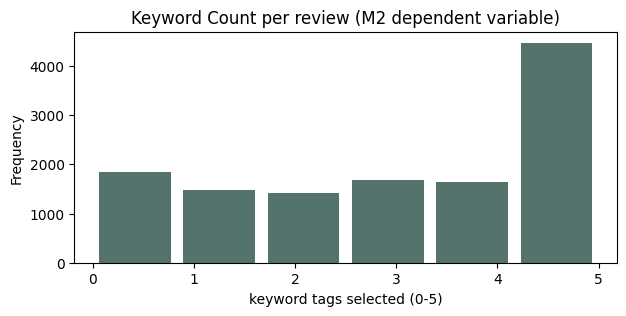

In [10]:
ax = df[["n_tags"]].plot(kind="hist", bins=6, rwidth=0.85, legend=False,
                         title="Keyword Count per review (M2 dependent variable)",
                         figsize=(7, 3), color="#55736D")
ax.set_xlabel("keyword tags selected (0-5)");

## 5. Descriptive tables / 기술통계

Produced by `10_descriptive_tables.py`, which also writes `proposal/tables_naver.tex`
that the proposal `\input`s. These are the appendix tables 표 1–표 3.

In [11]:
t1 = read("table1_variables.csv")
t1[["변수 종류", "변수 이름", "변수 설명"]] if t1 is not None else "run 10_descriptive_tables.py"


,변수 종류,변수 이름,변수 설명
0,종속변수 (DV),Revisit (재방문),해당 관광지를 2회차 이상 방문한 작성자의 리뷰 여부 (0/1)
1,종속변수 (DV),Keyword Count (키워드 수),"리뷰당 작성자가 선택한 키워드 수 (0~5), 정보 다양성 지표"
2,종속변수 (DV),Rating (별점),작성자가 부여한 별점 (1~5)
3,종속변수 (DV),Reactions (반응 수),"해당 리뷰에 반응을 남긴 이용자 수, 유용성 지표"
4,독립변수 (IV),Companion (동반자),방문 동반자 유형 더미: 혼자·연인·친구·아이·가족·동료
5,독립변수 (IV),Purpose (방문 목적),방문 목적 더미: 여행·나들이·일상·데이트·친목
6,독립변수 (IV),Waited (대기),방문 시 대기 경험 여부 (0/1)
7,독립변수 (IV),Reserved (예약),사전 예약 여부 (0/1)
8,독립변수 (IV),Sentiment (감성 점수),리뷰 텍스트의 감성 점수 (-1 부정 ~ 1 긍정)
9,독립변수 (IV),Tag themes (키워드 주제),키워드를 10개 주제로 분류한 더미: 시각·볼거리·혼잡·한적·시설·접근성·가족·가격·음식·물놀이


In [12]:
read("table2_descriptives.csv")

,Statistic,N,Mean,St. Dev.,Min,Median,Max
0,Revisit (재방문),12537,0.228603,0.419950,0.000,0.0000,1.0000
1,Keyword Count (키워드 수),12537,3.054718,1.859762,0.000,3.0000,5.0000
2,Rating (별점),4148,4.686355,0.738540,0.500,5.0000,5.0000
3,Reactions (반응 수),12537,1.284996,6.877882,0.000,0.0000,122.0000
4,Sentiment (감성 점수),9843,0.663835,0.448427,-0.973,0.8754,0.9879
5,Text Length (텍스트 길이),9843,112.515188,107.122608,14.000,71.0000,753.0000
6,Image Count (사진 수),12537,0.248465,1.470054,0.000,0.0000,20.0000
7,User Reviews (작성자 리뷰 수),12537,805.848528,1012.699936,1.000,449.0000,19082.0000
8,Review Age (리뷰 경과일),12537,502.726410,456.013603,0.000,370.0000,3957.0000


In [13]:
t3 = read("table3_correlations.csv", index_col=0)
t3.style.format("{:.3f}", na_rep="").background_gradient(cmap="RdBu_r", vmin=-.6, vmax=.6) \
    if t3 is not None else "missing"


,1,2,3,4,5,6,7,8,9
1. Revisit (재방문),1.000,,,,,,,,
2. Keyword Count (키워드 수),0.129,1.000,,,,,,,
3. Rating (별점),0.072,0.293,1.000,,,,,,
4. Reactions (반응 수),0.169,0.069,0.055,1.000,,,,,
5. Sentiment (감성 점수),-0.079,0.130,0.531,-0.036,1.000,,,,
6. Text Length (텍스트 길이),0.210,0.203,0.020,0.239,-0.096,1.000,,,
7. Image Count (사진 수),0.035,0.074,0.046,0.073,0.018,0.107,1.000,,
8. User Reviews (작성자 리뷰 수),0.255,0.003,0.038,0.185,-0.074,0.164,0.047,1.000,
9. Review Age (리뷰 경과일),-0.107,-0.325,-0.117,-0.057,-0.036,-0.133,-0.051,0.121,1.000


## 6. Model results / 모형 결과

`ratio` is an odds ratio for M1–M3 and an incidence rate ratio for M4:
above 1 raises the outcome, below 1 lowers it.

In [14]:
def effects(fname, title, alpha=0.05):
    d = read(fname)
    if d is None:
        print(f"{title}: missing"); return None
    d = d.rename(columns={d.columns[0]: "term"})
    sig = d[d["p"] < alpha].copy()
    sig["|effect|"] = (sig["ratio"] - 1).abs()
    sig = sig.sort_values("|effect|", ascending=False)
    print(f"\n{title}   {len(sig)} significant of {len(d)} terms")
    return sig[["term", "label", "ratio", "ci_low", "ci_high", "p"]].reset_index(drop=True)

effects("model1_revisit.csv", "M1  Revisit (odds ratios)")


M1  Revisit (odds ratios)   10 significant of 18 terms


,term,label,ratio,ci_low,ci_high,p
0,comp_alone,With: alone,1.6743,1.1744,2.3869,0.0044
1,ln_user_reviews,ln(1 + reviewer's reviews),1.5343,1.4157,1.6629,0.0000
2,waited,Waited to enter,0.4991,0.3477,0.7164,0.0002
3,comp_friend,With: friends,0.5702,0.4052,0.8025,0.0013
4,purp_travel,Purpose: travel,0.5787,0.4312,0.7768,0.0003
5,purp_outing,Purpose: outing,1.3206,1.0250,1.7014,0.0315
6,sentiment,Sentiment (-1 to 1),0.6815,0.5790,0.8021,0.0000
7,ln_length,ln(text length),1.3130,1.1451,1.5055,0.0001
8,purp_date,Purpose: date,0.7125,0.5249,0.9672,0.0297
9,n_tags,Keyword tags (0-5),1.1528,1.0703,1.2416,0.0002


In [15]:
effects("model2_keywords.csv", "M2  Keyword Count (odds ratios)")


M2  Keyword Count (odds ratios)   14 significant of 17 terms


,term,label,ratio,ci_low,ci_high,p
0,has_text,Wrote text (15+ chars),4.3927,3.7704,5.1178,0.0000
1,has_visit_info,Visit info provided,2.1787,1.6978,2.7958,0.0000
2,purp_travel,Purpose: travel,1.7849,1.5324,2.0790,0.0000
3,purp_outing,Purpose: outing,1.7761,1.5421,2.0455,0.0000
4,revisit,Revisitor (2+ visits),1.6205,1.3324,1.9708,0.0000
5,comp_alone,With: alone,1.6000,1.2169,2.1038,0.0008
6,purp_social,Purpose: socializing,1.5205,1.2481,1.8524,0.0000
7,purp_daily,Purpose: daily life,1.4578,1.2321,1.7249,0.0000
8,purp_date,Purpose: date,1.3273,1.1095,1.5880,0.0020
9,waited,Waited to enter,0.7517,0.6399,0.8831,0.0005


In [16]:
effects("model4_reactions.csv", "M4  Reactions (incidence rate ratios)")


M4  Reactions (incidence rate ratios)   9 significant of 26 terms


,term,label,ratio,ci_low,ci_high,p
0,ln_user_followers,ln(1 + reviewer's followers),1.9582,1.7677,2.1692,0.0000
1,ln_length,ln(text length),1.6418,1.4322,1.8821,0.0000
2,comp_colleague,With: colleagues,1.5796,1.0156,2.4567,0.0425
3,purp_outing,Purpose: outing,0.6552,0.4605,0.9323,0.0188
4,purp_travel,Purpose: travel,0.6660,0.4927,0.9001,0.0082
5,season_autumn,Visit: autumn,0.6765,0.5774,0.7927,0.0000
6,sentiment,Sentiment (-1 to 1),0.7588,0.6265,0.9190,0.0047
7,season_winter,Visit: winter,0.8142,0.6656,0.9959,0.0455
8,n_tags,Keyword tags (0-5),1.0925,1.0125,1.1788,0.0226


In [17]:
cv = read("model_metrics_cv.csv")
cv.pivot_table(index="metric", columns="model", values="value", aggfunc="first") \
  if cv is not None else "missing"


model,Model 1 revisit,"Model 1x revisit, extended",Model 2 keyword tags,"Model 2x keyword tags, extended",Model 4 reactions,Model 4b any reaction
metric,,,,,,
AUC,0.776,0.788,NaN,NaN,NaN,0.819
AUC any reaction (from predicted mean),NaN,NaN,NaN,NaN,0.806,NaN
Accuracy (always 'no'),0.765,0.765,NaN,NaN,NaN,NaN
Accuracy @0.5,0.788,0.794,NaN,NaN,NaN,NaN
Balanced accuracy,0.604,0.625,NaN,NaN,NaN,NaN
Brier,0.148,0.144,NaN,NaN,NaN,0.130
Brier (base rate),0.180,0.180,NaN,NaN,NaN,0.179
Exact accuracy (always mode),NaN,NaN,0.357,0.357,NaN,NaN
Exact accuracy (ordered),NaN,NaN,0.483,0.494,NaN,NaN


## 7. Where each file comes from / 파일 출처

Run order is the file-name order. `run_pipeline.py --list` prints the same thing.

**Careful:** `data/flat_naver.csv` is a leftover from an earlier export step and is *not*
refreshed by the Naver pipeline — it predates the re-scrape. Use `naver_dataset.csv`.

In [18]:
prov = pd.DataFrame([
    ("data/naver_reviews_raw.json",              "02_scrape_naver.py",        "raw scrape, one object per place"),
    ("data/analysis/naver/naver_dataset.csv",    "09_build_naver_dataset.py", "the modelling dataframe"),
    ("data/analysis/naver/model*.csv",           "09_02_naver_models.py",     "M1-M4 coefficients, CI, p"),
    ("data/analysis/naver/model_metrics_cv.csv", "09_02_naver_models.py",     "out-of-sample AUC / RMSE"),
    ("data/analysis/naver/vif.csv",              "09_02_naver_models.py",     "multicollinearity check"),
    ("data/analysis/rating_checks.csv",          "09_03_rating_checks.py",    "sentiment validated against stars"),
    ("data/analysis/naver/table1_variables.csv", "10_descriptive_tables.py",  "표 1 변수요약"),
    ("data/analysis/naver/table2_descriptives.csv", "10_descriptive_tables.py", "표 2 기술통계표"),
    ("data/analysis/naver/table3_correlations.csv", "10_descriptive_tables.py", "표 3 상관분석표"),
    ("proposal/tables_naver.tex",                "10_descriptive_tables.py",  "LaTeX the proposal \\input s"),
], columns=["File", "Produced by", "What it holds"])

prov["exists"] = prov["File"].map(lambda f: "yes" if list(ROOT.glob(f)) else "no")
prov

,File,Produced by,What it holds,exists
0,data/naver_reviews_raw.json,02_scrape_naver.py,"raw scrape, one object per place",yes
1,data/analysis/naver/naver_dataset.csv,09_build_naver_dataset.py,the modelling dataframe,yes
2,data/analysis/naver/model*.csv,09_02_naver_models.py,"M1-M4 coefficients, CI, p",yes
3,data/analysis/naver/model_metrics_cv.csv,09_02_naver_models.py,out-of-sample AUC / RMSE,yes
4,data/analysis/naver/vif.csv,09_02_naver_models.py,multicollinearity check,yes
5,data/analysis/rating_checks.csv,09_03_rating_checks.py,sentiment validated against stars,yes
6,data/analysis/naver/table1_variables.csv,10_descriptive_tables.py,표 1 변수요약,yes
7,data/analysis/naver/table2_descriptives.csv,10_descriptive_tables.py,표 2 기술통계표,yes
8,data/analysis/naver/table3_correlations.csv,10_descriptive_tables.py,표 3 상관분석표,yes
9,proposal/tables_naver.tex,10_descriptive_tables.py,LaTeX the proposal \input s,yes
